## Planar Segmentation : 
&nbsp;&nbsp;&nbsp; In this notebook , we will try to develop a robust way to do planar segmenetation , thus normal vector estimation. 
&nbsp;&nbsp;&nbsp; To be more precised , there two algorithms that we should detect , and these algorithms are : 
1. Seeding Algorithm : <br>
In this algorithm, we try to look for the initial neighborhood that we will grow into the planar plans. 
2. Exploration Algorithm : <br>
In this algorithms, we try to add more points to the initial neighborhood to have a planar plans. 

### Seeding Algorithm : 
&nbsp;&nbsp;&nbsp; In this section of the notebook, we will try to explore all of the seeding algorithm, and we will also try to see how well they perform. 
&nbsp;&nbsp;&nbsp; The seeding algorithms that we are going to explore as follows : <br>
1. regular KNN : 
In this seeding method, we try to create neighborhood of similar neighbors. 
2. weighted KNN : 
In this seeding method, we try to create neighborhood of similar neighbors using distance. 
3. highest local planarity : 
In this seeding method, we try to find the neighborhood with the highest planarity. 
4. Density : 
In this seeding method, we try to find the neighborhood with the highest density. 

In [205]:
from sklearn.neighbors import KNeighborsClassifier , NearestNeighbors
import numpy as np
from sklearn.neighbors import NearestNeighbors
from numpy.linalg import eig
import matplotlib.pyplot as plt 
import random 

In [206]:
def compute_eigen_values_vectors (A) : 
    return np.linalg.eigh(A)

In [207]:
def compute_covariance(dots) : 
    return np.cov(dots , rowvar=False)

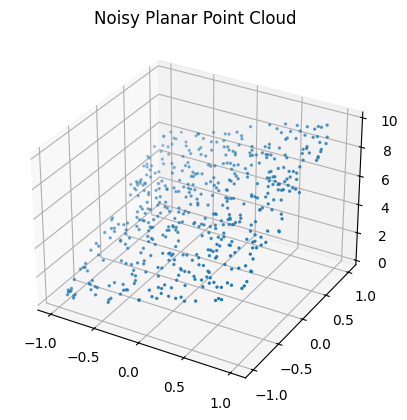

In [208]:
num_points = 500
x = np.random.uniform(-1, 1, num_points)
y = np.random.uniform(-1, 1, num_points)
z = 2 * x + 3 * y + 5
points = np.vstack((x, y, z)).T
noise = np.random.normal(0, 0.01, points.shape)
noisy_points = points + noise
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(noisy_points[:, 0], noisy_points[:, 1], noisy_points[:, 2], s=2)
ax.set_title("Noisy Planar Point Cloud")
plt.show()

#### Regular KNN : 
&nbsp;&nbsp;&nbsp; In this section, we will try to see how good the KNN is doing as seeding algorithm. 

In [209]:

def GetNeighbors(X , n_neighbors=5) :
    knn = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn.fit(X, np.zeros(X.shape[0])) 
    _, indices = knn.kneighbors(X, return_distance=True)
    neighbors = indices[:, 1:]
    return neighbors

In [210]:
print(GetNeighbors(noisy_points, n_neighbors=7))

[[ 50  18 179 135 358 265]
 [397 150 363  47 275 489]
 [106 294 420 400 249 457]
 ...
 [ 76  56 300 207 182 423]
 [374 454 368 163 414 348]
 [161 171 160  82  28 237]]


In [211]:
neighbors = GetNeighbors(noisy_points, n_neighbors=7)

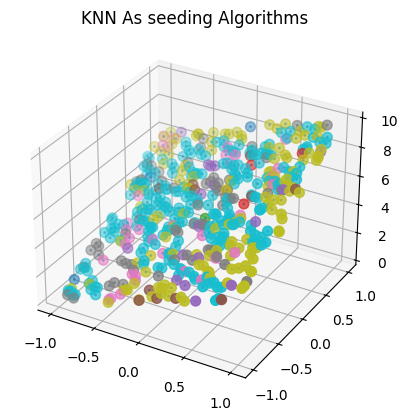

In [212]:
labels = np.full(len(noisy_points), -1)  
for cluster_id, indices in enumerate(neighbors):
    labels[indices] = cluster_id
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
plt.title("KNN As seeding Algorithms")
scatter = ax.scatter(noisy_points[:, 0], noisy_points[:, 1], noisy_points[:, 2] , s = 1)
ax.scatter(noisy_points[:, 0], noisy_points[:, 1], noisy_points[:, 2] ,c=labels, cmap='tab10', s = 50)
plt.show()

### Weighted KNN : 
&nbsp;&nbsp;&nbsp; In this section , we will see how good the weighted KNN does as a seeding algorithm. 

In [213]:
def GetWeightedNeighbors(X , n_neighbors=5): 
    knn = KNeighborsClassifier(n_neighbors=n_neighbors, weights='distance')
    knn.fit(X, np.zeros(X.shape[0])) 
    _, indices = knn.kneighbors(X, return_distance=True)
    neighbors = indices[:, 1:]
    return neighbors

In [214]:
neighbors = GetWeightedNeighbors(noisy_points, n_neighbors=7)

In [215]:
print(neighbors)

[[ 50  18 179 135 358 265]
 [397 150 363  47 275 489]
 [106 294 420 400 249 457]
 ...
 [ 76  56 300 207 182 423]
 [374 454 368 163 414 348]
 [161 171 160  82  28 237]]


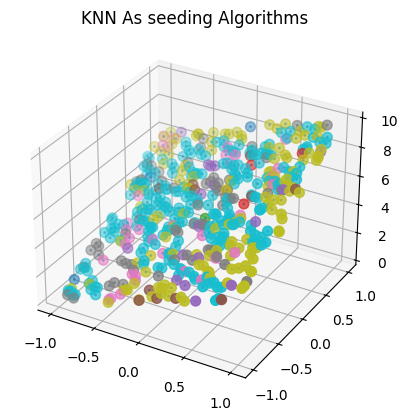

In [216]:
labels = np.full(len(noisy_points), -1)  
for cluster_id, indices in enumerate(neighbors):
    labels[indices] = cluster_id
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
plt.title("KNN As seeding Algorithms")
scatter = ax.scatter(noisy_points[:, 0], noisy_points[:, 1], noisy_points[:, 2] , s = 1)
ax.scatter(noisy_points[:, 0], noisy_points[:, 1], noisy_points[:, 2] ,c=labels, cmap='tab10', s = 50)
plt.show()

### Highest local planarity : 
&nbsp;&nbsp;&nbsp; In this section, we will see how well the local planarity is good as a seeding algorithm. 

In [217]:
def highest_local_planarity_efficient(X, n_neighbors=5):
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)
    dict = {}
    for i in range(X.shape[0]):
        neighbor_indices = indices[i, 1:]
        neighbor_points = X[neighbor_indices]

        if neighbor_points.shape[0] < 3:
            continue

        covariance_matrix = compute_covariance(neighbor_points)
        eigenvalues, _ = compute_eigen_values_vectors(covariance_matrix)
        eigenvalues.sort()

        sum_eigen = np.sum(eigenvalues)
        if sum_eigen > 1e-9:
            curvature = eigenvalues[0] / sum_eigen
            dict[i] = {
                "curvature": curvature,
                "neighbors" : neighbor_indices, 
                "seed" : i 
            }
    sorted_dict = sorted(dict.items(), key=lambda item: item[1]['curvature'], reverse=True)
    return sorted_dict

    

In [218]:
dict = highest_local_planarity_efficient(noisy_points, n_neighbors=7)

In [219]:
print("Suggested sorted seeds" , dict )

Suggested sorted seeds [(496, {'curvature': np.float64(0.015553467921247434), 'neighbors': array([258, 116, 270, 366, 160,  28, 297]), 'seed': 496}), (258, {'curvature': np.float64(0.013185436435455215), 'neighbors': array([116, 496, 160, 270, 366,  28, 297]), 'seed': 258}), (82, {'curvature': np.float64(0.01224683399472678), 'neighbors': array([297,  28, 237, 366, 160, 270, 271]), 'seed': 82}), (297, {'curvature': np.float64(0.011555738988379676), 'neighbors': array([ 82, 366,  28, 270, 160, 237, 310]), 'seed': 297}), (160, {'curvature': np.float64(0.011126638541516473), 'neighbors': array([ 28, 366, 270, 258, 499,  82, 297]), 'seed': 160}), (376, {'curvature': np.float64(0.01069868483307521), 'neighbors': array([102, 261,  48,  43, 400, 321, 457]), 'seed': 376}), (28, {'curvature': np.float64(0.01067730841732889), 'neighbors': array([366, 270, 160, 297,  82, 258, 496]), 'seed': 28}), (270, {'curvature': np.float64(0.01044514602675407), 'neighbors': array([366,  28, 160, 297, 496, 258

In [220]:
from mpl_toolkits.mplot3d import Axes3D

def plot_planarity_results(X, results, top_n=5):
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], color='black', alpha=0.5, s=1)
    for rank, (idx, data) in enumerate(results[:top_n]):
        ax.scatter(X[idx, 0], X[idx, 1], X[idx, 2], 
                   color='red', s=60, edgecolors='black', label='Seed' if rank == 0 else "")
        neighbors = data["neighbors"]
        ax.scatter(X[neighbors, 0], X[neighbors, 1], X[neighbors, 2], 
                   color='blue', s=80, alpha=0.8, label='Neighborhood' if rank == 0 else "")

    ax.legend()
    plt.title(f"Top {top_n} Planar Seeds & Neighborhoods")
    plt.show()


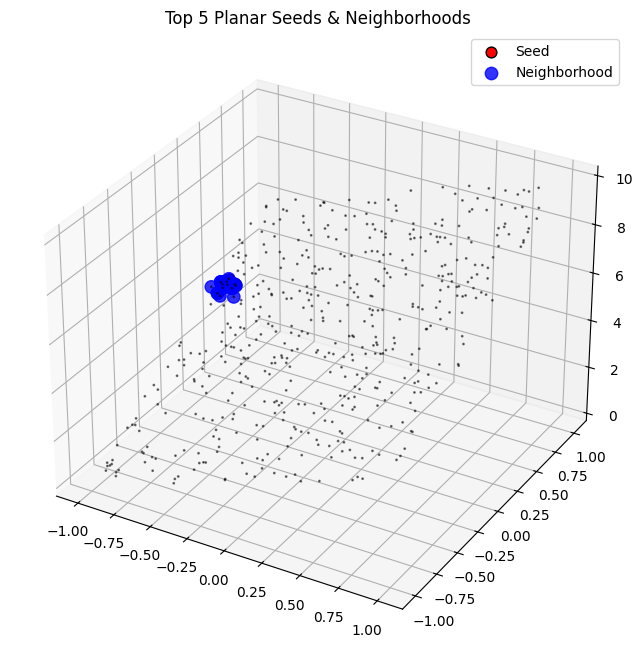

In [221]:
plot_planarity_results(noisy_points , dict , top_n=5)

### Density : 
&nbsp;&nbsp;In this section, we will see how well is relying on the density as a seeding function. 

In [222]:
def get_density_based_neighbors(X, n_neighbors=5):
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)
    dict = {}
    for i in range(X.shape[0]):
        density = np.sum(np.exp(-distances[i, 1:] ** 2))
        neighbor_indices = indices[i, 1:]
        dict[i] = {
            "density" : density , 
            "seed" : i , 
            "neighbors" : neighbor_indices
        }
    sorted_dict = sorted(dict.items(), key=lambda item: item[1]['density'], reverse=True)
    return sorted_dict

In [223]:
print("sorted Dict " , get_density_based_neighbors(noisy_points))

sorted Dict  [(28, {'density': np.float64(4.979191305028385), 'seed': 28, 'neighbors': array([366, 270, 160, 297,  82])}), (366, {'density': np.float64(4.975229128767288), 'seed': 366, 'neighbors': array([ 28, 270, 297, 160,  82])}), (430, {'density': np.float64(4.972304643475073), 'seed': 430, 'neighbors': array([345,  60,  44, 302, 482])}), (270, {'density': np.float64(4.969137423901223), 'seed': 270, 'neighbors': array([366,  28, 160, 297, 496])}), (86, {'density': np.float64(4.96511294662636), 'seed': 86, 'neighbors': array([317,  94, 422,  45, 201])}), (44, {'density': np.float64(4.9648388174641), 'seed': 44, 'neighbors': array([345, 379, 430, 302, 351])}), (141, {'density': np.float64(4.964684558790768), 'seed': 141, 'neighbors': array([391,  96, 348, 295, 323])}), (60, {'density': np.float64(4.963139136105116), 'seed': 60, 'neighbors': array([482, 430, 130, 345,  44])}), (96, {'density': np.float64(4.962581027776004), 'seed': 96, 'neighbors': array([295, 323, 141, 391, 195])}), 

In [224]:
dict = get_density_based_neighbors(noisy_points)
for point in dict : 
    print(point[1]['density'])

4.979191305028385
4.975229128767288
4.972304643475073
4.969137423901223
4.96511294662636
4.9648388174641
4.964684558790768
4.963139136105116
4.962581027776004
4.961957149672532
4.960232178995835
4.959208303659304
4.958606771564873
4.958265329882348
4.957271686600257
4.956929076508716
4.956673086910835
4.954080518179319
4.953318623905213
4.953299565251774
4.9531982726082155
4.952508186073998
4.952289600730943
4.95138663715526
4.950506606862401
4.949839113652424
4.949732005369825
4.948412548962335
4.94836930886265
4.9482959081104125
4.948232626108362
4.947401476479564
4.947250867874876
4.946416950065554
4.945643845765603
4.945515278237395
4.945122287567686
4.944836865561478
4.944459582860739
4.944131035277842
4.943860487253502
4.943337574813856
4.943056508095054
4.941935085554838
4.9417367573328
4.941193478632922
4.938544011657689
4.937564532916412
4.937554177264891
4.9372327347070035
4.936643829708144
4.936445095677621
4.9361506387809415
4.936132403542917
4.935488791351717
4.93515914241

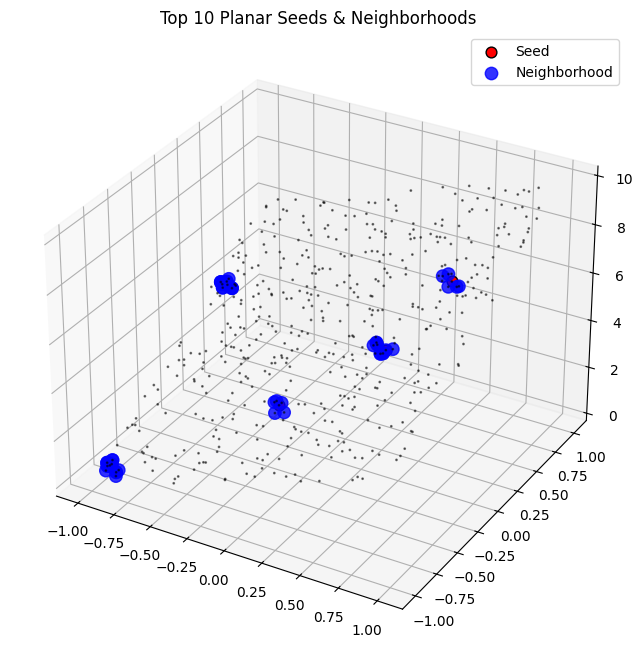

In [225]:
plot_planarity_results(noisy_points , dict , top_n=10)

## Exploration Algorithm : 
&nbsp;&nbsp;&nbsp; In this section of this notebook, we will try to develop an algorithm that explore the points and grows the neighborhood more and get the final planar plans. <br>
&nbsp;&nbsp;&nbsp; We will explore all of possible solution , but essentially it relies on the thresholding based on smallest eigen value. This will allow growing neighborhood into existing planas which will allow the detection of planar plans. <br>
&nbsp;&nbsp; &nbsp; We will start by exploring the possiblity of region growing using **per axis region growing**. but it might fail against some edge cases so before we will implement **edge cases testing mechanism**. So, we will start by implementing that first of all. 

### Edge cases testing mechanism: 
&nbsp;&nbsp;&nbsp; In the section, we will try to implement edge cases testing mechanism. The **edge cases** are as follows : <br>
1. Opposite Normal Direction : 
Same plane but normals computed from opposite sides. It should be detected as one plane. 
2. Normal Flip at Boundaries : 
Points where normal estimation is unstable at edges, it shouldn't fragment plane. 
3. Nearly Parallel plans : 
Plans that are 5 degree apart , this is set to test the angular tolerance limits. 
4. Intersecting Planes :
Three orthogonal planes meeting , this is useful for edge detection. 
5. noisy plane : 
clean plan with increasing noise levels. 
6. Degenerate Case : 
There too few points for reliable PCA. 

In [313]:
def create_rectangular_grid(width, height):
    return [(x, y) for x in range(width) for y in range(height)]
grid = create_rectangular_grid(10, 10)      
small_grid = create_rectangular_grid(5, 5)
from random import random 

In [323]:
import numpy as np
from random import random
import numpy.random as npr

class EdgeCaseTester:
    def __init__(self, grid=None, small_grid=None):
        self.epsilon = 1e-6
        if grid is None:
            x = np.linspace(-1, 1, 5)
            y = np.linspace(-1, 1, 5)
            self.grid = [(xi, yi) for xi in x for yi in y]
        else:
            self.grid = grid

        if small_grid is None:
            s = np.linspace(-1, 1, 3)
            self.small_grid = [(xi, yi) for xi in s for yi in s]
        else:
            self.small_grid = small_grid

    def normal_vector_ambiguity(self): 
        plane_top = [(x, y, 0.01 * random()) for x, y in self.grid]  
        plane_bottom = [(x, y, -0.01 * random()) for x, y in self.grid]  
        return np.vstack((plane_bottom, plane_top))

    def nearly_parallel_planes(self):
        plane1 = [(x, y, 0) for x, y in self.grid]
        plane2 = [(x, y, x * 0.087) for x, y in self.grid]  
        return np.array(plane1 + plane2)

    def intersecting_planes(self): 
        xy_plane = [(x, y, 0) for x, y in self.small_grid]
        xz_plane = [(x, 0, z) for x, z in self.small_grid]  
        yz_plane = [(0, y, z) for y, z in self.small_grid]
        return np.array(xy_plane + xz_plane + yz_plane)

    def noisy_planes(self): 
        clean = [(x, y, 0) for x, y in self.grid]
        noisy = [(x, y, npr.normal(0, 0.2)) for x, y in self.grid]
        return np.array(clean + noisy)

    def degenerate_cases(self): 
        line_points = [(i, 0, 0) for i in range(3)]
        return np.array(line_points)


### Proposed Algorithm : 
&nbsp;&nbsp;&nbsp; In this section of the notebook, we will try to implement the first version of the algorithm and iteratively improve till we reach a state where we can pass all the test against the edge cases by the end of that we will also try to compare our method will already existing ones. <br>
&nbsp;&nbsp;&nbsp; We will be iterating over the following the next parameters till we get to an algorithm that passes the whole tests : 
1. seeding algorithm : 
especially the fact of either using density based or planarity based for the seeding algorithm. 
2. region growing : 
how we should add points and how should we iterate to explore multiple possible planar plans across our plan. 

#### First approach : 
&nbsp;&nbsp;&nbsp; In this approach , we relied on the fact that one of the definition of planar plans is as follows : <br> 
"a planar plane's points share the same normal vector and it is a plan that can be represented by less axis than the dimensions it is drawn in , it can rely on 2 axis if it is drawn in 3D". 

In [228]:
def GetDensityBasedNeighbors(X, n_neighbors=5):
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)

    density = np.zeros(X.shape[0])
    for i in range(X.shape[0]):
        density[i] = np.sum(np.exp(-distances[i, 1:] ** 2))
    densest_index = np.argmax(density)
    neighbor_indices = indices[densest_index, 1:]
    neighbors = X[neighbor_indices]
    return X[densest_index], neighbors , densest_index , neighbor_indices


In [229]:
# Get neighbors within the exploration part 
def make_axis_distance(axis):
    '''Create a distance function that measures distance along a specific axis.
    axis can be the following values 
    0 -> compute the distance per x axis 
    1 -> compute the distance per y axis 
    2 -> compute the distance per z axis 
    '''
    def distance_fn(x, y):
        return abs(x[axis] - y[axis])
    return distance_fn
def get_neighbors_within_exploration(X, axis , n_neighbors=5):
    per_axis_distance = make_axis_distance(axis)
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1 , metric = per_axis_distance)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)
    return distances , indices 

In [230]:
# Initial Algorithm implementation 
def initial_algorithm_implementation (X ,axis , n_neighbors ,  threshold_eigen_value=0.1 ): 
    # step 1 : get the seeds using one of the suggested methods above 
    seed, neighbors , seed_index , neighbor_index = GetDensityBasedNeighbors(X, n_neighbors=5)
    if seed is None:
        return 
    # step 2 : compute the covariance matrix of the seed and its neighbors
    covariance_matrix = compute_covariance(np.vstack((seed, neighbors)))
    # step 3 : compute the eigen values and vectors of the covariance matrix
    eig_val , _ = compute_eigen_values_vectors(covariance_matrix)
    # step 4 : check if the smallest eigen value is above the threshold
    eig_val.sort()
    initial_smallest_eig_value = eig_val[0]
    # step 5 : we will start to explore the neighbors of the seed 
    _, indices = get_neighbors_within_exploration(X, axis=axis, n_neighbors=n_neighbors)
    to_explore = list(neighbor_index)
    explored = set(neighbor_index)
    planar_plan = np.vstack((seed, neighbors))
    
    # step 6 : explore the neighbors until we reach a point where the smallest eigen value is below the threshold
    while to_explore : 
        idx = to_explore.pop()
        local_neighbors = indices[idx][1:]
        local_points = X[local_neighbors]
        local_covariance_matrix = compute_covariance(np.vstack((planar_plan , local_points)))
        eig_val , _ = compute_eigen_values_vectors(local_covariance_matrix)
        eig_val.sort()
        eig_val = eig_val[0]
        if eig_val > threshold_eigen_value : 
            return planar_plan 
        else : 
            planar_plan = np.vstack((planar_plan , local_points))
            for i in local_neighbors : 
                if i not in explored : 
                    to_explore.append(i)
                    explored.add(i)
    return planar_plan

In [231]:
planar_plan = initial_algorithm_implementation(noisy_points, 0 , 5 , 0.1 )

In [232]:
print ("Number of points detected as planar plans : " , len(planar_plan))

Number of points detected as planar plans :  371


In [233]:
print ("Number of points in the plan (clean + Noise) : " , len(noisy_points))

Number of points in the plan (clean + Noise) :  500


In [234]:
print (planar_plan[0])

[-0.89933368  0.38203688  4.30042055]


##### Remark : 
&nbsp;&nbsp;&nbsp; Bear in mind , this is just an intial version and it is not even iterative in the exploration we will try to improve it in a bit. 

In [235]:
z_axis_planar_plan = initial_algorithm_implementation(noisy_points, 2 , 5 , 0.1 )

In [236]:
print("Number of points detected as planar plan along z axis :" , len(z_axis_planar_plan))

Number of points detected as planar plan along z axis : 826


In [237]:
y_axis_planar_plan = initial_algorithm_implementation(noisy_points, 1 , 5 , 0.1 )

In [238]:
print("Number of points detected as planar plan along y axis : " , len(y_axis_planar_plan) )

Number of points detected as planar plan along y axis :  801


Text(0.5, 0.92, 'version 2 of the algorithm')

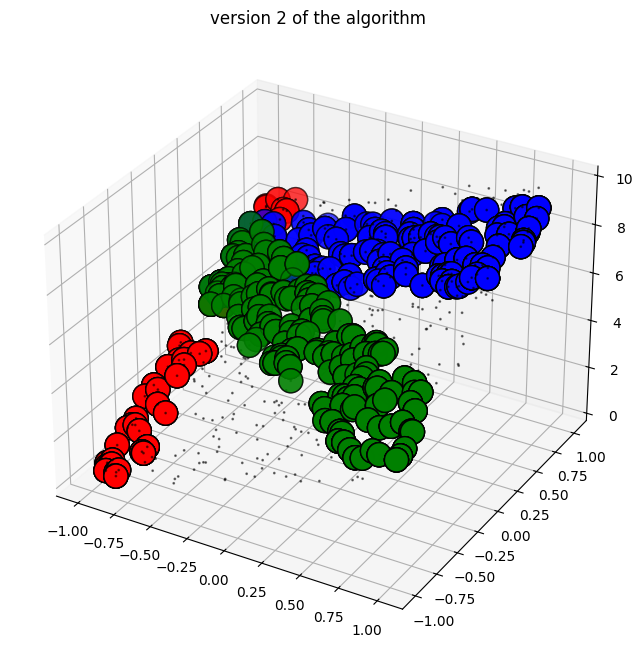

In [239]:
# now we will plot all the planar plans detected along all of the axis 

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(noisy_points[:, 0], noisy_points[:, 1], noisy_points[:, 2], color='black', alpha=0.5, s=1)
ax.scatter(planar_plan[:, 0], planar_plan[:, 1], planar_plan[:, 2], 
 color='red', s=300, edgecolors='black', label='x_axis detection')
ax.scatter(y_axis_planar_plan[:, 0], y_axis_planar_plan[:, 1], y_axis_planar_plan[:, 2], 
 color='blue', s=300, edgecolors='black', label='y_axis detection')
ax.scatter(z_axis_planar_plan[:, 0], z_axis_planar_plan[:, 1], z_axis_planar_plan[:, 2], 
 color='green', s=300, edgecolors='black', label='z_axis detection')
plt.title("version 2 of the algorithm")

##### Remark : 
&nbsp;&nbsp;&nbsp; In the plot above , we can see that the current implementation of the algorithm missed the detection of the whole plan as planar plan with some noise points and that is due to the fact that the plan is kinda shifted by a degree. <br>
&nbsp;&nbsp;&nbsp; This is a flaw that we should fix in the second implementation of the algorithm one way to do is we will look for neighboring region based on the distance regardless of the axis. 

In [240]:
def explore_using_distance(X , n_neighbors=5): 
    knn = KNeighborsClassifier(n_neighbors=n_neighbors, weights='distance')
    knn.fit(X, np.zeros(X.shape[0])) 
    return  knn.kneighbors(X, return_distance=True)
    

In [241]:
def Planar_Segmentation_Version_2 (X , n_neighbors ,  threshold_eigen_value=0.1 ): 
    # step 1 : get the seeds using one of the suggested methods above 
    seed, neighbors , seed_index , neighbor_index = GetDensityBasedNeighbors(X, n_neighbors=5)
    if seed is None:
        return 
    # step 2 : compute the covariance matrix of the seed and its neighbors
    covariance_matrix = compute_covariance(np.vstack((seed, neighbors)))
    # step 3 : compute the eigen values and vectors of the covariance matrix
    eig_val , _ = compute_eigen_values_vectors(covariance_matrix)
    # step 4 : check if the smallest eigen value is above the threshold
    eig_val.sort()
    initial_smallest_eig_value = eig_val[0]
    # step 5 : we will start to explore the neighbors of the seed 
    _, indices = explore_using_distance(X,  n_neighbors=n_neighbors)
    to_explore = list(neighbor_index)
    explored = set(neighbor_index)
    planar_plan = np.vstack((seed, neighbors))
    
    # step 6 : explore the neighbors until we reach a point where the smallest eigen value is below the threshold
    while to_explore : 
        idx = to_explore.pop()
        local_neighbors = indices[idx][1:]
        local_points = X[local_neighbors]
        for point in local_neighbors : 
            local_covariance_matrix = compute_covariance(np.vstack((planar_plan , X[point])))
            eig_val , _ = compute_eigen_values_vectors(local_covariance_matrix)
            eig_val.sort()
            eig_val = eig_val[0]
            ratio = eig_val / initial_smallest_eig_value
            if ratio > threshold_eigen_value : 
                # we will not use that point 
                print("skip this point") 
            else : 
                print ("exploring this point")
                planar_plan = np.vstack((planar_plan , local_points))
                if point not in explored : 
                    to_explore.append(point)
                    explored.add(point)
    # we will turn the planar_plan from array to a set 
    return planar_plan

In [255]:
planar_plan =Planar_Segmentation_Version_2 (noisy_points,  n_neighbors=5, threshold_eigen_value=2)

exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring this point
exploring thi

In [256]:
len(planar_plan)

6054

Text(0.5, 0.92, 'version 3 of the algorithm')

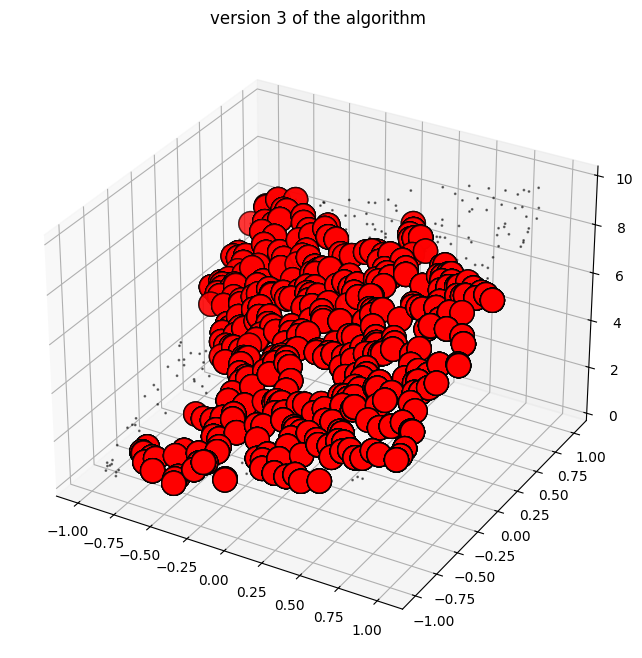

In [257]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(noisy_points[:, 0], noisy_points[:, 1], noisy_points[:, 2], color='black', alpha=0.5, s=1)
ax.scatter(planar_plan[:, 0], planar_plan[:, 1], planar_plan[:, 2], 
 color='red', s=300, edgecolors='black')
plt.title("version 3 of the algorithm")

we can clearly see that the algorithm is doing well especially that it almost covered the whole area of the data. 

##### Remark :
&nbsp;&nbsp;&nbsp; In this section, we will try to make it iterative and then compare the angles between two planar plans to see whether they are the same or not so that we can grow regions and also combine planar plans if they belong to the same planar plans. <br>
&nbsp;&nbsp;&nbsp; We will follow the following approach : 
1. iteratively explore the space: 
grow multiple planar plans and explore multiple possibilities. 
2. combine planar plans : 
after combining the planar plans we will try to combine them using the angle in between the two normal vectors. 

In [406]:
def planar_segmentation_version_4(X, n_neighbors, threshold_eigen_value=0.1):
    neighbor_dict = get_density_based_neighbors(X, n_neighbors)
    planar_plans = {}
    explored = set()
    plan_id = 0
    
    for proposedseed in neighbor_dict:
        seed_idx = proposedseed[1]['seed']
        if seed_idx in explored:
            continue
        
        seed = X[seed_idx]
        neighbors = X[proposedseed[1]['neighbors']]
        covariance_matrix = compute_covariance(np.vstack((seed, neighbors)))
        eig_val, eig_vec = compute_eigen_values_vectors(covariance_matrix)
        sorted_indices = np.argsort(eig_val)
        eig_val = eig_val[sorted_indices]
        eig_vec = eig_vec[:, sorted_indices]
        initial_smallest_eig_value = eig_val[0]

        to_explore = list(proposedseed[1]['neighbors'])
        explored.update(to_explore)
        explored.add(seed_idx)
        planar_plan = np.vstack((seed, neighbors))
        last_eig_vec = eig_vec[0]
        #lamba 
        la_1 = eig_val[0]
        la_2 = eig_val[1]
        la_3 = eig_val[2]

        while to_explore:
            idx = to_explore.pop()
            local_neighbors = neighbor_dict[idx][1]['neighbors']
            for index_point in local_neighbors:
                if index_point in explored:
                    continue
                point = X[index_point]
                local_covariance_matrix = compute_covariance(np.vstack((planar_plan, point)))
                eig_val, eig_vec = compute_eigen_values_vectors(local_covariance_matrix)
                sorted_indices = np.argsort(eig_val)
                eig_val = eig_val[sorted_indices]
                eig_vec = eig_vec[:, sorted_indices]
                last_eig_vec = eig_vec[:, 0]
                #lamba 
                la_1 = eig_val[0]
                la_2 = eig_val[1]
                la_3 = eig_val[2]
                
                ratio = eig_val[0] / initial_smallest_eig_value
                if ratio <= threshold_eigen_value:
                    planar_plan = np.vstack((planar_plan, point))
                    to_explore.append(index_point)
                    explored.add(index_point)

        planar_plans[plan_id] = {
            "planar_plan": planar_plan,
            "eigen_vector": last_eig_vec , 
            "planarity_score" : (la_2 -la_1 )/ la_3
        }
        plan_id += 1

    return planar_plans


In [338]:
results_planar_plans = planar_segmentation_version_4(noisy_points , 7  , 2 )

In [339]:
len(results_planar_plans)

4

In [340]:
print (results_planar_plans[0])

{'planar_plan': array([[-0.94752594, -0.88091928,  0.48306185],
       [-0.98149848, -0.85844962,  0.45835246],
       [-0.93820325, -0.87537031,  0.53921495],
       ...,
       [ 0.08832343, -0.94882572,  2.26992038],
       [ 0.45796588,  0.07312233,  6.1559183 ],
       [ 0.53629694, -0.99015755,  3.11070998]], shape=(497, 3)), 'eigen_vector': array([ 0.53466506,  0.80167339, -0.26730703])}


In [341]:
len(results_planar_plans[0]['planar_plan'])

497

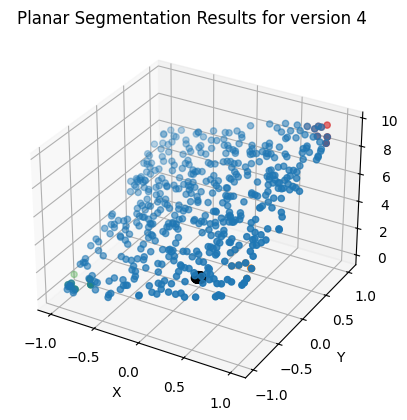

In [342]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each cluster with a different color
for i in range(len(results_planar_plans)): 
    cluster = results_planar_plans[i]['planar_plan']
    ax.scatter(cluster[:, 0], cluster[:, 1], cluster[:, 2])
ax.scatter(noise[:,0] , noise[:,1] , noise[:,2] , c='black' , s=40)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.title("Planar Segmentation Results for version 4 ")
plt.show()

##### Remark : 
&nbsp;&nbsp;&nbsp; We can see that the current algorithm covers the whole area , now we shall to the part of merging two or more planar plans into a one plan. <br>
&nbsp;&nbsp;&nbsp; The merging process will rely on the current vectors aligned with all the areas and we will try to merge according to the angle between the two vectors. <br>
&nbsp;&nbsp;&nbsp; We can clearly see that we have four planar plans and we will try to find a way to merge them in our case , they are all belong to a bigger planar plan. 

In [343]:
def plot_test_results (results):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    # Plot each cluster with a different color
    for i in range(len(results)): 
        cluster = results[i]['planar_plan']
        ax.scatter(cluster[:, 0], cluster[:, 1], cluster[:, 2])
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    plt.title("Planar Segmentation Results for version 4 ")
    plt.show()

In [344]:
tester = EdgeCaseTester()

In [345]:
planar_plans = planar_segmentation_version_4(tester.normal_vector_ambiguity() , 7 , 2)

In [346]:
len(planar_plans)

3

In [348]:
for i in range(3) : 
    print (planar_plans[i]['eigen_vector'])

[-0.0015324   0.00135115  0.99999791]
[ 0.00317439 -0.00586591  0.99997776]
[2.07977320e-03 3.33337679e-04 9.99997782e-01]


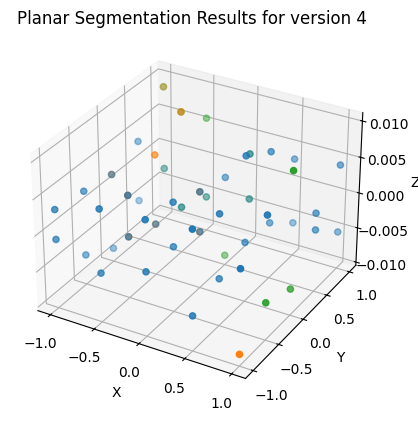

In [349]:
plot_test_results(planar_plans)

In [350]:
planar_parellel_plans = planar_segmentation_version_4(tester.nearly_parallel_planes() , 7 , 2)

C:\Users\user.DESKTOP-OMQ89VA\AppData\Local\Temp\ipykernel_9200\4183106589.py:41: RuntimeWarning: divide by zero encountered in scalar divide
  ratio = eig_val[0] / initial_smallest_eig_value
C:\Users\user.DESKTOP-OMQ89VA\AppData\Local\Temp\ipykernel_9200\4183106589.py:41: RuntimeWarning: invalid value encountered in scalar divide
  ratio = eig_val[0] / initial_smallest_eig_value


In [351]:
len(planar_parellel_plans)

6

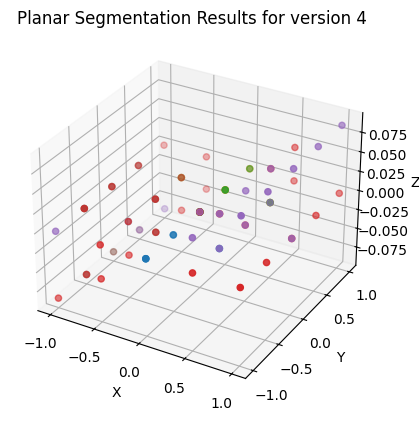

In [352]:
plot_test_results(planar_parellel_plans)

In [353]:
intersecting_planes = planar_segmentation_version_4(tester.intersecting_planes() , 7 , 2)

In [354]:
len(intersecting_planes)

3

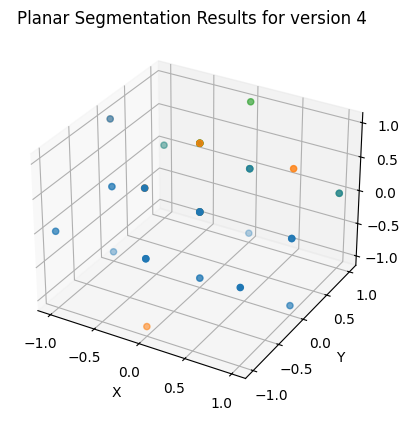

In [355]:
plot_test_results(intersecting_planes)

In [359]:
degenerate_plans =  planar_segmentation_version_4(tester.degenerate_cases() , 2 , 2)

In [360]:
len(degenerate_plans)

1

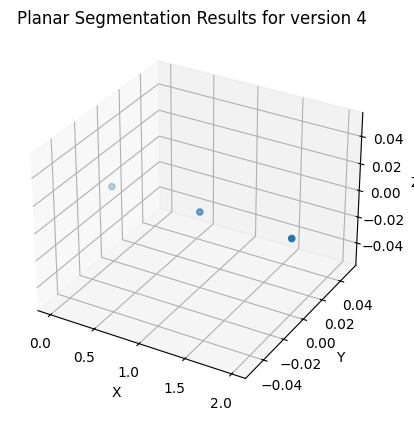

In [361]:
plot_test_results(degenerate_plans)

### Overall Review : 
&nbsp;&nbsp;&nbsp; Overall , the algorithm is solid and it is performing really well , but it fails at some cases but we can improve the current state to be more efficient and aligns with the edge cases throught the merging of the resulting vectors. And that is what we will try to do in the following section of the notebook. 

### Merging Planar Plan Into Global Plan : 
&nbsp;&nbsp;&nbsp; In this section of the notebook , we will try to develop an algorithm that will take the outputed normal vectors compare them based on the angle between them and merge them if it is possible we will also need an **angle threshold** between two normal vectors to take them as one global planar plan. 

In [407]:
def angle_between_normals(n1, n2):
    n1 = n1 / np.linalg.norm(n1)
    n2 = n2 / np.linalg.norm(n2)
    dot_product = np.clip(np.dot(n1, n2), -1.0, 1.0)  
    theta = np.arccos(dot_product)
    return min(theta, np.pi - theta)

In [408]:
# minor testing 
vec1 = np.array([0.1, 0.9, 0.3])
vec2 = np.array([0.1, 1.2, 0.3])

angle_rad = angle_between_normals(vec1, vec2)
print (angle_rad)
angle_deg = np.degrees(angle_rad)

print(f"Angle between planes: {angle_deg:.2f}°")


0.0802243389749016
Angle between planes: 4.60°


In [416]:
def final_version_normal_vector_estimation(X, n_neighbors, eigen_value_threshold, angle_threshold):
    planar_plans = planar_segmentation_version_4(X, n_neighbors, eigen_value_threshold)
    size = len(planar_plans)
    merged_plans = []
    used_indices = set()  
    print(size)

    for i in range(size):
        if i in used_indices:
            continue 

        current_plan = planar_plans[i]['planar_plan']
        current_normal = planar_plans[i]['eigen_vector']
        print(planar_plans[i]['planarity_score'])
        for j in range(i + 1, size):
            if j in used_indices:
                continue 
            
            next_plan = planar_plans[j]['planar_plan']
            next_normal = planar_plans[j]['eigen_vector']
            angle = np.degrees(angle_between_normals(current_normal, next_normal))
            if angle < angle_threshold:
                print(f"Merging plan {i} with plan {j} due to angle {angle:.2f}°")
                current_plan = np.vstack((current_plan, next_plan))
                used_indices.add(j)  
        
        merged_plans.append(current_plan)

    return merged_plans


        
    

In [418]:
merged_plans = final_version_normal_vector_estimation(tester.nearly_parallel_planes(), 15, 2, 2)

2
0.7862610820691235
0.548688547081057


In [419]:
len(merged_plans)

2

#### Metrics To Be Used : 
&nbsp;&nbsp;&nbsp; In this section of the code we can talk about the possible ### Metrics To Be Used

In this section of the code, we outline the metrics that will be used to evaluate the quality and reliability of the detected planar segments.

1. **Planarity Score**  
   - **Definition:** Measures how closely the points in a segment lie on a plane.  
   - **Computation:** Based on PCA eigenvalues \((\lambda_1 \ge \lambda_2 \ge \lambda_3)\) of the covariance matrix:  
     \[
     \text{Planarity} = \frac{\lambda_2 - \lambda_3}{\lambda_1}
     \]
   - **Interpretation:**  
     - Values close to **1** → strong planar structure.  
     - Values close to **0** → weak or noisy planar structure.  


&nbsp;&nbsp;&nbsp; When using this method make sure to track the planarity so you can tune in the parameters like **neighbors/ angle_threshold/ eigen_value_threshold**. 
